# LeNet

LeNet-5 описали Ян Лекун и соавторы в 1998 году в работе о распознавании документов. Модель создавали для рукописных цифр: свёртки выделяли признаки, пулинг уменьшал карты признаков, а последние слои определяли класс. [Оригинальная статья](https://leon.bottou.org/papers/lecun-98h).

Здесь проверим, как LeNet-5 справится с цветными изображениями CIFAR-10 размером 32×32. Вместо одного канала первый свёрточный слой у нас принимает три. Оставляем три свёртки с `Tanh` и два слоя среднего пулинга, а на выходе получаем 10 чисел - логиты для каждого из классов.

Ниже показана наша адаптация LeNet.

<img src="images/lenet5.svg" alt="Схема LeNet-5" height="600">

In [4]:
import torch.nn as nn
import torch
import pandas as pd
from pathlib import Path
from torch.utils.data import TensorDataset
import sys
sys.path.append("../utils")
from data_utils import (
    images_to_tensor, train_dataset_split, create_dataloader,
    calculate_mean_std, AutoAugumentationDataset, TestImagesDataset,
)

In [5]:
SEED = 52
torch.manual_seed(SEED)

## Работа с данными

In [6]:
# Исходные изображения храним в uint8 без деления на 255.
X_train, y_train = images_to_tensor(
    "../data/train",
    "../data/trainLabels.csv",
)

Разделим размеченные данные на train и val: 80% изображений пойдут на обучение, а оставшиеся 20% — на проверку после каждой эпохи

In [7]:
ds_train = TensorDataset(X_train, y_train)

In [8]:
ds_train, ds_val = train_dataset_split(ds_train, train_size=0.8, random_seed=SEED)

### Стандартизация и аугментация данных

После разделения данных один раз вычислим mean и std каждого цветового канала по исходному train в шкале 0–255. Эти фиксированные статистики используем для train, val и test. Деление на 255 не требуется: пиксели и статистики находятся в одной шкале.

Train храним в uint8. Четыре процесса DataLoader применяют AutoAugment к отдельным изображениям на CPU и готовят батчи. После переноса батча на MPS (или выбранное DEVICE) переводим его в float32 и стандартизируем непосредственно перед моделью: `(x.float() - mean) / std`. Mean и std для каждого батча заново не считаются.

К train перед стандартизацией применим `AutoAugmentPolicy.CIFAR10`. При каждом обращении к изображению стратегия случайно выбирает одну из подготовленных пар операций. Каждая операция срабатывает со своей вероятностью. Среди них есть:

- Геометрические изменения: поворот (Rotate), сдвиг по горизонтали и вертикали (TranslateX, TranslateY), наклон (ShearY).
- Изменения цвета и тона: яркость (Brightness), насыщенность (Color), контраст (Contrast), резкость (Sharpness), инверсия (Invert), соляризация (Solarize), уменьшение числа цветов (Posterize), автоматическая настройка контраста (AutoContrast) и выравнивание гистограммы (Equalize).

Val стандартизируем целиком один раз на CPU. Test читаем в uint8 и стандартизируем батчами на DEVICE той же функцией, что и train. Аугментаций для val и test нет.

Подробности изменений и результатов замеров: [docs/lenet_optimization.md](../docs/lenet_optimization.md).

Примеры того, как меняются изображения:
- 1.png: лягушка сдвинута вправо
- 2.png: грузовик сдвинут вверх
- 7.png: птица стала темнее
- 8.png: у лошади изменились цвета и контраст

<img src="images/autoaugment_examples.png" alt="Примеры AutoAugment" width="450">

In [9]:
# Статистики считаем один раз по исходному train в шкале 0–255.
mean, std = calculate_mean_std(ds_train)

# Свежие аугментации на CPU; изображения остаются uint8 до переноса на DEVICE.
ds_train_aug = AutoAugumentationDataset(ds_train)

# Val не меняется между эпохами: стандартизируем один раз целиком на CPU.
val_x = X_train[ds_val.indices].float()
val_x.sub_(mean.view(1, -1, 1, 1))
val_x.div_(std.view(1, -1, 1, 1))
ds_val_ready = TensorDataset(val_x, y_train[ds_val.indices])

In [10]:
BATCH_SIZE = 2048

In [11]:
dl_train = create_dataloader(
    ds_train_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    random_seed=SEED,
    num_workers=4,
)
dl_val = create_dataloader(
    ds_val_ready,
    batch_size=BATCH_SIZE,
    shuffle=False,
    random_seed=SEED,
)

## Создание класса LeNet

In [12]:
class LeNet5(nn.Module):
    """Упрощённая адаптация LeNet-5 для изображений CIFAR-10 размером 32x32."""

    def __init__(
        self,
        in_channels: int = 3,
        output_size: int = 10,
        image_size: tuple[int, int] = (32, 32)
    ):

        super().__init__()

        modules = []
        conv_layers = [6, 16, 120]

        in_ = in_channels # количество входных каналов для свёртки
        for i in range(len(conv_layers)): # цикл добавления свёрточных слоёв, 1 слой - (свёртка + активация + пуллинг)

            # свёртка
            modules.append(nn.Conv2d(
                in_channels=in_,
                out_channels=conv_layers[i],
                kernel_size=5,
                stride=1,
                padding=0,
            ))
            in_ = conv_layers[i]

            modules.append(nn.Tanh()) # слой активации после какждой свёртки

            if i != len(conv_layers)-1: # после каждой свёртки кроме последней добавляем слой пулинга
                modules.append(nn.AvgPool2d(kernel_size=2, stride=2))

        #вычиляем на искусственном примере размер картинки, который получился после всех свёрток
        with torch.no_grad():
            sample = torch.zeros(1, in_channels, *image_size)
            in_features = nn.Sequential(*modules)(sample).flatten(1).shape[1]

        # после всех свёрточных слоёв распрямляем значения в вектор, чтобы подать на вход линейному слою
        modules.append(nn.Flatten())

        # линейный слой на 84 нейрона
        modules.append(nn.Linear(in_features, 84))
        modules.append(nn.Tanh())

        # в конце добавляем выходной слой, дающий предсказания (логиты) для каждого из классов
        modules.append(nn.Linear(84, output_size))

        self.network = nn.Sequential(*modules)

    def forward(self, x):
        return self.network(x)

In [13]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Устройство: {DEVICE}")

Устройство: mps


In [14]:
# Один набор коэффициентов для всех train/test батчей; создаём на DEVICE один раз.
mean_device = mean.to(DEVICE).view(1, -1, 1, 1)
std_device = std.to(DEVICE).view(1, -1, 1, 1)

def standardize_batch(batch_x):
    """Принимает uint8 [0, 255] на DEVICE, возвращает стандартизированный float32."""
    return (batch_x.float() - mean_device) / std_device

In [15]:
lenet5 = LeNet5().to(DEVICE)
loss_func = nn.CrossEntropyLoss()
# weight_decay=1e-4 - небольшой стартовый штраф т.к. AutoAugment уже есть,
# поэтому не усиливаем регуляризацию слишком сильно
optimizer = torch.optim.Adam(lenet5.parameters(), lr=5e-4, weight_decay=1e-4)

## Обучение

In [16]:
import sys
sys.path.append("../utils")
from train_utils import train, test

Обучим модель и сохраним веса той эпохи, на которой точность на val окажется самой высокой. Train стандартизируется батчами на DEVICE через `train_preprocess`; val поступает в модель уже стандартизированным. Графики обновляем раз в 10 эпох. После изменения utils нужно перезапустить kernel и выполнить ноутбук с начала.

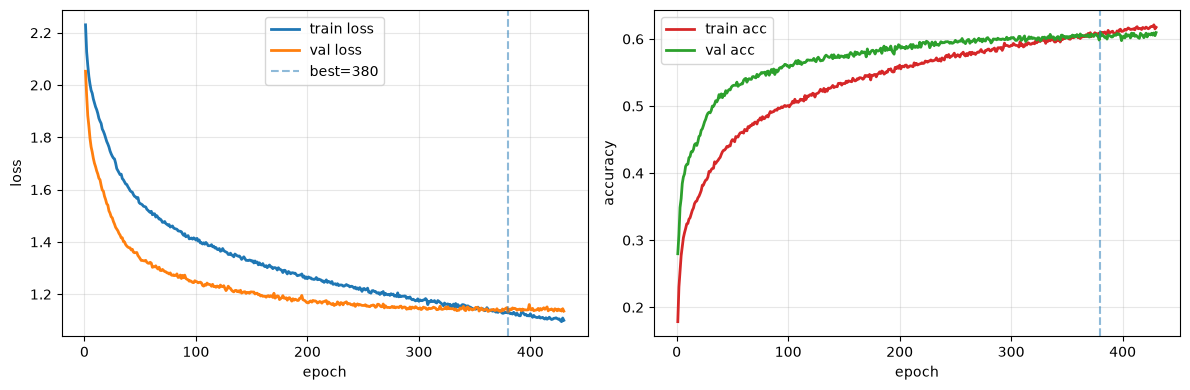

Ранняя остановка на эпохе 430: val_acc не улучшалась 50 эпох
Best epoch = 380, best val_acc = 0.6100


,0
0,0.61
1,380.00


In [17]:
Path("models").mkdir(exist_ok=True)

train(
    lenet5, optimizer, loss_func,
    dl_train, dl_val,
    "models/lenet5.pth",
    DEVICE,
    EPOCH_COUNT=1000,
    patience=50,
    log_every=10,
    train_preprocess=standardize_batch,
)

## Тестирование

Загрузим веса лучшей эпохи. Тестовые картинки будем читать в uint8 батчами в порядке sampleSubmission.csv. После переноса на DEVICE применим `standardize_batch` с теми же mean и std исходного train, затем сохраним предсказания в submission. Аугментаций на test нет.

In [ ]:
lenet_best = LeNet5(3, 10, (32, 32)).to(DEVICE)
lenet_best.load_state_dict(torch.load('models/lenet5.pth', map_location=DEVICE))
lenet_best.eval()

In [ ]:
ds_test = TestImagesDataset(
    "../data/test",
    "../data/sampleSubmission.csv",
)

In [ ]:
dl_test = create_dataloader(
    ds_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
)
class_names = sorted(pd.read_csv("../data/trainLabels.csv")["label"].unique())

In [ ]:
submission = test(
    lenet_best,
    dl_test,
    class_names,
    "../data/sampleSubmission.csv",
    "lenet_submission.csv",
    DEVICE,
    preprocess=standardize_batch,
)

## Итог

В ходе работы была реализована и обучена адаптированная архитектура **LeNet-5** для классификации изображений датасета CIFAR-10. До добавления аугментации и стандартизации максимальная точность на валидационной выборке составила **57,11 %** и была достигнута на 225-й эпохе.

Результат объясняется особенностями архитектуры, предложенной в 1998 году преимущественно для распознавания рукописных символов. По сравнению с более современными сетями LeNet-5 имеет относительно простую структуру и ограниченные возможности извлечения сложных признаков, необходимых для классификации цветных изображений. Тем не менее для архитектуры своего времени LeNet-5 стала значимым достижением и продемонстрировала применимость свёрточных нейронных сетей к задачам распознавания изображений.


# Разбор изменений в коде LeNet

Документ описывает внесённые правки по файлам: какие параметры добавлены,
какие строки заменены и как новые функции вызываются из ноутбука.
Фрагменты «было» относятся к коду до оптимизации; «стало» — к текущему коду.

## 1. utils/data_utils.py

### 1.1. PILToTensor вместо ToTensor

Было:

```python
from torchvision.transforms import ToTensor, v2
```

Стало:

```python
from torchvision.transforms import PILToTensor, v2
```

`ToTensor()` преобразовывал наши RGB PNG в float32 и делил пиксели на 255.
`PILToTensor()` сохраняет uint8 и значения 0–255, формируя `[C, H, W]`.
Загрузка исходных изображений теперь всегда использует uint8.

### 1.2. images_to_tensor: единый формат результата

Внутри функции заменена строка:

```python
# Было:
to_tensor = ToTensor()

# Стало:
to_tensor = PILToTensor()
```

Сигнатура функции сохраняет только пути, число каналов и признак наличия
меток. Параметров выбора типа изображения нет. Возвращаемый `X` всегда
имеет тип `torch.uint8`, форму `[N, C, H, W]` и значения 0–255.
Чтение CSV, кодирование классов и формирование `y` не менялись.

### 1.3. TestImagesDataset: uint8 при каждом чтении PNG

Конструктор сохраняет прежние аргументы: пути к изображениям и CSV,
число каналов. Преобразование создаётся без выбора режима:

```python
self.to_tensor = PILToTensor()
```

`__getitem__` по-прежнему читает один PNG и возвращает результат этого
преобразования. Порядок определяется ID из `sampleSubmission.csv`.
Все изображения test заранее в RAM не загружаются.

### 1.4. AutoAugumentationDataset: только аугментация

Раньше метод безусловно выполнял float32 → uint8 → float32:

```python
image, label = self.dataset[index]
image = (image * 255).round().to(torch.uint8)
image = self.augment(image)
image = image.to(torch.float32) / 255
return image, label
```

Теперь загрузчик уже выдаёт uint8, поэтому достаточно:

```python
def __getitem__(self, index):
    image, label = self.dataset[index]
    return self.augment(image), label
```

Конструктор принимает только `dataset`. Удалены переключатель типа,
проверка dtype и оба преобразования типов вокруг аугментации.
Результат AutoAugment остаётся uint8. Обёртке нужно передавать исходные
изображения до стандартизации; метка класса не изменяется.

### 1.5. calculate_mean_std и StandardizationDataset

Для вычисления статистик добавлен перевод выбранного train в float32:

```python
X_train = ds_train.dataset.tensors[0][ds_train.indices].float()
mean = X_train.mean(dim=(0, 2, 3))
std = X_train.std(dim=(0, 2, 3), correction=0)
```

`ds_train.indices` выбирает только train после разделения. `.float()`
позволяет посчитать среднее и отклонение, сохраняя числовую шкалу 0–255.
Статистики имеют форму `[C]` и вычисляются один раз до аугментаций.

В `StandardizationDataset`, используемом AlexNet, перевод в float32
теперь также указан явно непосредственно перед стандартизацией:

```python
# Для пары (изображение, метка):
return (image.float() - self.mean) / self.std, label

# Для отдельного изображения test:
return (data.float() - self.mean) / self.std
```

Таким образом, обе модели загружают и аугментируют uint8. LeNet переводит
train/test в float32 на устройстве при обработке батча. AlexNet делает
это внутри `StandardizationDataset` на CPU. Результат стандартизации
должен быть вещественным, поскольку содержит дробные и отрицательные значения.

### 1.6. create_dataloader: настройка процессов

В функцию добавлен аргумент `num_workers: int = 0`. Создание загрузчика
теперь содержит:

```python
return DataLoader(
    ds,
    batch_size=batch_size,
    shuffle=shuffle,
    generator=g,
    num_workers=num_workers,
    persistent_workers=num_workers > 0,
    prefetch_factor=2 if num_workers > 0 else None,
)
```

Назначение трёх новых аргументов:

| Аргумент | Что делает |
|---|---|
| `num_workers` | Число дочерних процессов, которые вызывают Dataset и собирают батчи на CPU |
| `persistent_workers` | Сохраняет эти процессы между эпохами, пока используется загрузчик |
| `prefetch_factor` | Задаёт число батчей, которые каждый worker может готовить заранее |

При `num_workers=4` включаются постоянные процессы и prefetch по два батча
на worker. При `num_workers=0` постоянные процессы выключены,
`prefetch_factor=None`, выдача данных идёт в основном процессе.

Генератор с `random_seed` сохранён. Аугментации при переходе от нуля
к четырём workers могут отличаться даже при том же seed, поскольку
теперь случайные операции выполняются в нескольких процессах.

## 2. utils/train_utils.py

### 2.1. train: новый аргумент train_preprocess

В конец сигнатуры добавлен:

```python
train_preprocess=None,
```

В обучающем цикле между переносом данных и вызовом модели вставлены
две строки:

```python
for batch_x, batch_y in dl_train:
    batch_x, batch_y = batch_x.to(device), batch_y.to(device)
    if train_preprocess is not None:
        batch_x = train_preprocess(batch_x)
    y_pred = model(batch_x)
```

`train_preprocess` — функция, переданная как аргумент. В LeNet это
`standardize_batch`. Запись `train_preprocess=standardize_batch` передаёт
саму функцию; скобки не ставятся, потому что вызвать её нужно позже,
для каждого полученного батча.

К моменту вызова `batch_x` уже находится на `device`, поэтому перевод
в float32, вычитание mean и деление на std выполняются на этом устройстве.
Возвращаемое значение заменяет `batch_x`, и модель получает подготовленные
вещественные входы. `batch_y` дополнительная обработка не затрагивает.

При `None` вызов пропускается. Это сохраняет возможность передавать
в `train()` загрузчик уже подготовленных изображений, как в AlexNet.

В цикле валидации новый callback не вызывается. Для LeNet загрузчик val
уже содержит стандартизированные float32-тензоры. Повторное применение
стандартизации там исказило бы входы.

### 2.2. test: новый аргумент preprocess

В конец сигнатуры добавлен `preprocess=None`.

Было:

```python
for batch_x in dl_test:
    logits = model(batch_x.to(device))
```

Стало:

```python
for batch_x in dl_test:
    batch_x = batch_x.to(device)
    if preprocess is not None:
        batch_x = preprocess(batch_x)
    logits = model(batch_x)
```

Это даёт test тот же порядок обработки: перенос батча, вызов переданной
функции, модель. В LeNet передаётся та же `standardize_batch`, что и в train.
Поэтому коэффициенты и формула обработки совпадают.

Определение класса через `argmax`, сопоставление с `class_names` и сборка
submission продолжают выполняться после получения логитов.

## 3. notebooks/LeNet.ipynb

### 3.1. Импорты и загрузка исходных данных

Из импорта `data_utils` убран `StandardizationDataset`, поскольку LeNet
теперь выполняет стандартизацию в других местах. Удалён неиспользуемый
импорт `Callable`, добавлен `Path` для создания папки весов.

Вызов загрузки использует единый формат uint8 без дополнительных параметров:

```python
X_train, y_train = images_to_tensor(
    "../data/train",
    "../data/trainLabels.csv",
)
```

Создание `TensorDataset` и разделение train/val оставлены прежними.

### 3.2. Подготовка train и val

Было:

```python
mean, std = calculate_mean_std(ds_train)
ds_train_aug = AutoAugumentationDataset(ds_train)
ds_train_ready = StandardizationDataset(ds_train_aug, mean, std)
ds_val_ready = StandardizationDataset(ds_val, mean, std)
```

Стало:

```python
mean, std = calculate_mean_std(ds_train)
ds_train_aug = AutoAugumentationDataset(ds_train)

val_x = X_train[ds_val.indices].float()
val_x.sub_(mean.view(1, -1, 1, 1))
val_x.div_(std.view(1, -1, 1, 1))
ds_val_ready = TensorDataset(val_x, y_train[ds_val.indices])
```

`ds_train_ready` больше не создаётся: стандартизация train перенесена
из `Dataset.__getitem__` в функцию обработки готового батча.

Для val создаётся отдельная float32-копия выбранных изображений.
`sub_` и `div_` изменяют её на месте: сначала вычитают mean, затем делят
на std. Исходный `X_train` в uint8 эти операции не изменяют.

Изображения и метки val выбираются по одинаковым индексам, поэтому их
соответствие сохраняется. `ds_val_ready` хранит готовые значения в RAM;
повторять преобразование на каждой эпохе не требуется.

### 3.3. Создание загрузчиков

Train теперь получает `ds_train_aug` напрямую и включает четыре workers:

```python
dl_train = create_dataloader(
    ds_train_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    random_seed=SEED,
    num_workers=4,
)
```

Val использует `ds_val_ready` и значение `num_workers=0` по умолчанию.
Размер батча сохранён: `BATCH_SIZE = 2048`.

### 3.4. Новая ячейка standardize_batch

После определения `DEVICE`, до создания модели, добавлена ячейка:

```python
mean_device = mean.to(DEVICE).view(1, -1, 1, 1)
std_device = std.to(DEVICE).view(1, -1, 1, 1)

def standardize_batch(batch_x):
    return (batch_x.float() - mean_device) / std_device
```

`mean.to(DEVICE)` и `std.to(DEVICE)` копируют коэффициенты на выбранное
устройство один раз. Эти строки находятся вне функции и цикла обучения.

`.view(1, -1, 1, 1)` превращает `[3]` в `[1, 3, 1, 1]`. `-1` означает,
что PyTorch сам определяет длину канала из числа элементов.
Так коэффициенты распространяются на весь батч `[B, 3, 32, 32]`:
каждый канал использует свои mean и std для всех изображений и пикселей.

Внутри функции `.float()` создаёт вещественное представление uint8-батча
на том же устройстве. Затем выполняется `(x - mean) / std`.
Деления на 255 нет: и пиксели, и рассчитанные статистики находятся
в шкале 0–255. Mean и std внутри функции не пересчитываются.

Функция использует переменные `mean_device` и `std_device`, определённые
в ноутбуке. Она вызывается основным процессом после получения батча,
а не процессами DataLoader.

### 3.5. Вызов train

Добавлено создание папки весов и передача функции:

```python
Path("models").mkdir(exist_ok=True)

train(
    lenet5, optimizer, loss_func,
    dl_train, dl_val,
    "models/lenet5.pth",
    DEVICE,
    EPOCH_COUNT=1000,
    patience=50,
    log_every=10,
    train_preprocess=standardize_batch,
)
```

`exist_ok=True` позволяет выполнять ячейку повторно, когда папка уже есть.
`log_every` изменён с 1 на 10, поэтому графики строятся реже.
Валидация и выбор лучшей модели продолжают выполняться каждую эпоху.

### 3.6. Подготовка test и вызов test

Test всегда читает uint8:

```python
ds_test = TestImagesDataset(
    "../data/test",
    "../data/sampleSubmission.csv",
)
```

Обёртка `ds_test_ready = StandardizationDataset(...)` убрана.
В `create_dataloader` передаётся сам `ds_test`. В вызов `test()` добавлен
аргумент:

```python
preprocess=standardize_batch,
```

Если оставить прежнюю обёртку и одновременно передать этот аргумент,
стандартизация выполнится дважды. Поэтому оба изменения сделаны вместе.

### 3.7. Текст и сохранённые выводы ячеек

Поясняющие markdown-ячейки обновлены под новый код. Выводы изменённых
кодовых ячеек и их `execution_count` очищены: старые графики и метрики
не должны выглядеть результатами выполнения новой версии.
Остальные ячейки и историческое обсуждение точности сохранены.

## 4. Как новые части кода связаны между собой

```text
LeNet.ipynb: images_to_tensor(...)
    ↓
TensorDataset → random_split → calculate_mean_std(ds_train)
    ↓
AutoAugumentationDataset(ds_train)
    ↓
create_dataloader(..., num_workers=4)
    ↓
train(..., train_preprocess=standardize_batch)
    ↓ для каждого батча
batch_x.to(device)
    ↓
standardize_batch(batch_x)
    ↓
model(batch_x)
```

Для val путь заканчивается подготовкой `ds_val_ready` до обучения:
в цикле валидации выполняются перенос на устройство и вызов модели.
Для test `TestImagesDataset(...)` выдаёт изображения в загрузчик,
а `test(preprocess=standardize_batch)` применяет обработку после переноса.

## 5. Проверки и запуск

После внесения правок проверены синтаксис обоих Python-файлов, всех кодовых
ячеек LeNet и форматирование diff. Полное выполнение нового ноутбука
и повторный замер именно этой версии не проводились.

Предыдущие измерения вариантов находятся в
[benchmarks/REPORT.md](../benchmarks/REPORT.md). Они послужили основанием
для выбора четырёх workers; это отдельный документ с результатами замеров.
В бенчмарке прежняя float32-схема сохранена в локальном классе
`LegacyFloatAugmentation` исключительно для сравнения с исходным baseline.
Рабочие загрузчики и AutoAugment используют единый uint8-формат.

Для запуска нужно перезапустить kernel и выполнить ноутбук с начала:
обычный повторный `from ... import ...` в уже работающем kernel может
использовать загруженную ранее версию модуля. Загрузчики, изображения
и статистики тоже должны быть созданы заново согласованной версией кода.

Ноутбук ожидает PNG/CSV в `data/train`, `data/trainLabels.csv`, `data/test`
и `data/sampleSubmission.csv`. Архив CIFAR-10, скачанный для бенчмарка,
имеет другой формат и напрямую эти пути не заменяет.
